# Question 3 (core) 

#### In this question we verify that a closed orbit is found using the verlet algorithm, also checking that the total energy remains constant. An analytical derived solution for v0 is also found at the bottom.

##### Verifying the orbit is closed: 

We have that the acceleration vector field (ax, ay) can be defined by:

$a\hat{x} = \frac{-GMr\hat{x}}{|r^3|}$


$a\hat{y} = \frac{-GMr\hat{y}}{|r^3|}$

Now that we have the acceleration functions, we can use the velocity Verlet algorithm:

$$\mathbf{r}_{k+1} = \mathbf{r}_k + \mathbf{v}_k \, dt + \frac{1}{2} \mathbf{a}(\mathbf{r}_k) \, dt^2$$
 

$$\mathbf{v}_{k+1} = \mathbf{v}_k + \frac{1}{2} \big( \mathbf{a}(\mathbf{r}_k) +  \mathbf{a}(\mathbf{r}_{k+1})\big) \, dt$$

Setting the values for G(gravational constant) and M(Mass of the sun), and the initial velocity and position, we can create a loop which appends a storage array (storing the postion of the planet) using the velocity Verlet algorithm, giving us an array we can use to plot the trajectory of the planet, and verifying that the planet's orbit is a closed loop (which we do indeed find looking at the outputs below the code cell). 

##### Verifying that the total energy stays constant:

As for verifying that the energy stays constant, all that is left to do is define a function for the total energy by summing the kinetic energy and potential energy: $\textbf{E = T + V}$. 

$\textbf{T} = \frac{1}{2} \sum_{i} m_i |\dot{\mathbf{r}}_i|^2$

$\textbf{V} = -G \sum_{i>j} \frac{m_i m_j}{|\mathbf{r}_j - \mathbf{r}_i|}.$

By creating an storage list for the total energy (E) at each time step, we can plot a graph to verify that the total energy stays constant. This graph can be seen in the outputs of the code cell below, and we can indeed see that E remains constant throughout the orbit. 

We have the first graph representing 2d space, with the orbit depicted by the blue curve, and the central body depicted by the red dot at the origin:

The second plot reveals that the total energy stays constant during the orbital period with time on the x-axis and energy on the y-axis:


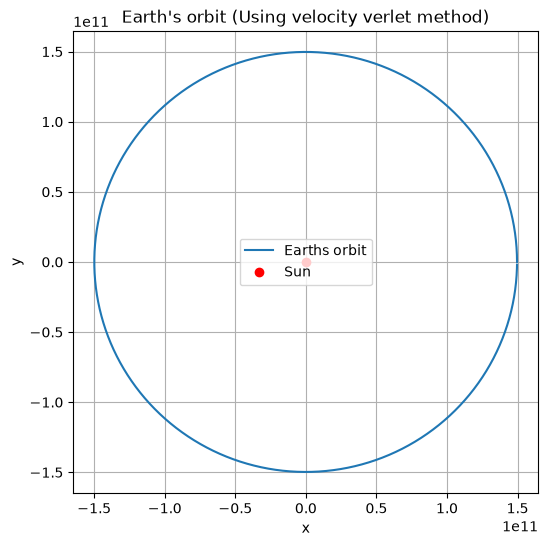

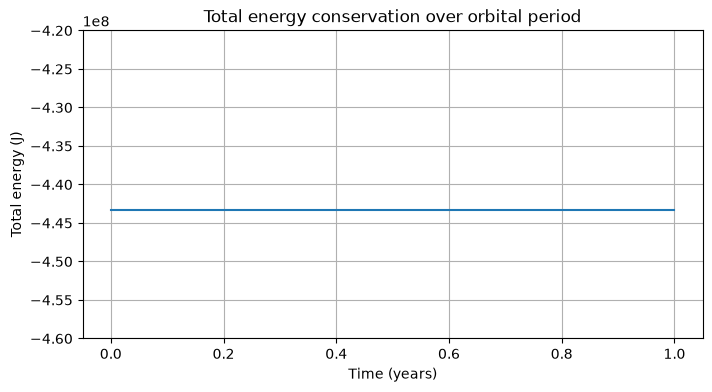

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Fixing the parameters
G = 6.67348e-11
Mass_sun = 1.989e30
R_orbit = 149.6e9

# Creating arrays to later be used for the planets velocity and position values
r0 = np.array([R_orbit, 0.0])
v0 = np.array([0.0, 29800.0])

# Defining the acceleration function to be used for the algorithm. 
def acceleration(r):
    x = r[0]
    y = r[1]

    r_abs = (x**2 + y**2) ** 0.5
    ax = -G * Mass_sun * x / (r_abs**3)
    ay = -G * Mass_sun * y / (r_abs**3)

    return np.array([ax, ay])

# Setting the time step as 1 day (in seconds) and the number of steps as the number of days in a year. 
dt = 86400
steps = int((366 * 24 * 3600) / dt)

# Creating new arrays for the position and velocity values using the initial values. 
r = np.array(r0)
v  = np.array(v0)

# Creating lists to be appended in the algorithm 
r_orbit = []
energy = []
t = []

# Defining the total energy function 
def total_energy(pos_vec, vel_vec, mass=1.0):
    
    T = 0.5 * mass * (vel_vec[0]**2 + vel_vec[1]**2)
    r_abs = (pos_vec[0]**2 + pos_vec[1]**2)**0.5
    V = -G * Mass_sun * mass / r_abs
    
    return T + V

# Applying the velocity verlet algorithm 
for step in range(steps):
    r_orbit.append(r)
    energy.append(total_energy(r, v))
    t.append(step * dt)

    a = acceleration(r)
    r_update = r + v * dt + 0.5 * a * (dt**2)
    a_update = acceleration(r_update)
    v_update = v + 0.5 * (a + a_update) * dt 

    r = r_update 
    v = v_update 

r_orbit = np.array(r_orbit)

# plotting required results
print('We have the first graph representing 2d space, with the orbit depicted by the blue curve, and the central body depicted by the red dot at the origin:')
    
plt.figure(figsize=(6, 6))
plt.plot(r_orbit[:, 0], r_orbit[:, 1], label='Earths orbit')
plt.plot(0, 0, "ro", label='Sun')
plt.title("Earth's orbit (Using velocity verlet method)")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show 

print()

print('The second plot reveals that the total energy stays constant during the orbital period with time on the x-axis and energy on the y-axis:')

plt.figure(figsize=(8, 4))
plt.plot(np.array(t) / (365 * 24 * 3600), energy)
plt.title('Total energy conservation over orbital period')
plt.xlabel('Time (years)')
plt.ylabel('Total energy (J)')
plt.grid(True)
plt.ylim(-4.6e8, -4.2e8)
plt.show()


#### Analytical derivation of initial speed v0:





For a circular orbit of radius \(r\), the gravitational force provides the required centripetal force. Using Newton's law of universal gravitation and the equation for circular motion:
\begin{equation*}
    \frac{G M m}{r^2} = \frac{m v_0^2}{r}
\end{equation*}
where \(M\) is the mass of the Sun, \(m\) is the mass of the orbiting body (the Earth), and \(r = R\) is the orbital radius. 

Canceling the mass of the orbiting body \(m\) and one factor of \(r\) from the denominator gives:
\begin{equation*}
    \frac{G M}{R} = v_0^2
\end{equation*}
Taking the square root yields the analytical expression for the orbital speed:
\begin{equation*}
    v_0 = \sqrt{\frac{G M}{R}}
\end{equation*}

